## Dataset Overview: Building Energy Consumption
**MCC Data Science Track — Week 3: Regression**

This dataset contains **1,100 records** (merged from the 1,000-row training split and 100-row testing split) designed for regression modeling. The goal is to predict a building's total energy consumption based on its structural characteristics, occupancy, and environmental conditions.

### Features Description
| Feature | Data Type | Role | Description |
| :--- | :--- | :--- | :--- |
| **`Building Type`** | Categorical | Feature | Category of the building (`Residential`, `Commercial`, `Industrial`) |
| **`Square Footage`** | Numerical | Feature | Total floor area of the building (sq. ft.) |
| **`Number of Occupants`** | Numerical | Feature | Number of people inside the building |
| **`Appliances Used`** | Numerical | Feature | Count of active appliances in use |
| **`Average Temperature`** | Numerical | Feature | Average ambient temperature (°C) |
| **`Day of Week`** | Categorical | Feature | Whether the record was logged on a `Weekday` or `Weekend` |
| **`Energy Consumption`** | Numerical | **Target ($y$)** | Total energy consumed by the building |

**Source:** [Kaggle — Energy Consumption Dataset](https://www.kaggle.com/datasets/govindaramsriram/energy-consumption-dataset-linear-regression)

In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [2]:
df = pd.read_csv(r"/home/ae/ME/study/DS_Microsoft_S_Club_Content_tasks/mentor/week3-Regression/session/energy_consumption.csv")
df.sample(5)

,Building Type,Square Footage,Number of Occupants,Appliances Used,Average Temperature,Day of Week,Energy Consumption
1013,Commercial,29187,82,39,23.54,Weekday,4991.64
724,Residential,49638,29,15,20.88,Weekday,4517.48
360,Residential,38641,9,3,19.52,Weekend,3484.46
835,Industrial,45584,52,11,20.78,Weekend,5415.31
1056,Residential,9655,87,13,22.86,Weekend,2998.47


# 1. Data Understanding

In [3]:
df.columns

Index(['Building Type', 'Square Footage', 'Number of Occupants',
       'Appliances Used', 'Average Temperature', 'Day of Week',
       'Energy Consumption'],
      dtype='str')

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1100 entries, 0 to 1099
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Building Type        1100 non-null   str    
 1   Square Footage       1100 non-null   int64  
 2   Number of Occupants  1100 non-null   int64  
 3   Appliances Used      1100 non-null   int64  
 4   Average Temperature  1100 non-null   float64
 5   Day of Week          1100 non-null   str    
 6   Energy Consumption   1100 non-null   float64
dtypes: float64(2), int64(3), str(2)
memory usage: 60.3 KB


In [5]:
df.isnull().sum()

Building Type          0
Square Footage         0
Number of Occupants    0
Appliances Used        0
Average Temperature    0
Day of Week            0
Energy Consumption     0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
# Numerical Static Description 
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Square Footage,1100.0,25500.527273,14236.955632,560.00,13203.750,25785.50,37536.75,49997.00
Number of Occupants,1100.0,48.268182,29.127624,1.00,22.000,47.00,73.00,99.00
Appliances Used,1100.0,25.730000,14.116209,1.00,13.000,26.00,38.00,49.00
Average Temperature,1100.0,22.559745,7.122357,10.05,16.365,22.81,28.76,34.99
Energy Consumption,1100.0,4168.191273,924.278723,1683.95,3510.460,4189.69,4859.51,6530.60


In [8]:
# Categorical Static Description
df.select_dtypes('str').describe().T

,count,unique,top,freq
Building Type,1100,3,Residential,387
Day of Week,1100,2,Weekday,551


In [9]:
cat_cols = df.select_dtypes('str').columns
for col in cat_cols:
    display(df[col].value_counts())

Building Type
Residential    387
Commercial     362
Industrial     351
Name: count, dtype: int64

Day of Week
Weekday    551
Weekend    549
Name: count, dtype: int64

# 2. EDA and Feature Eng

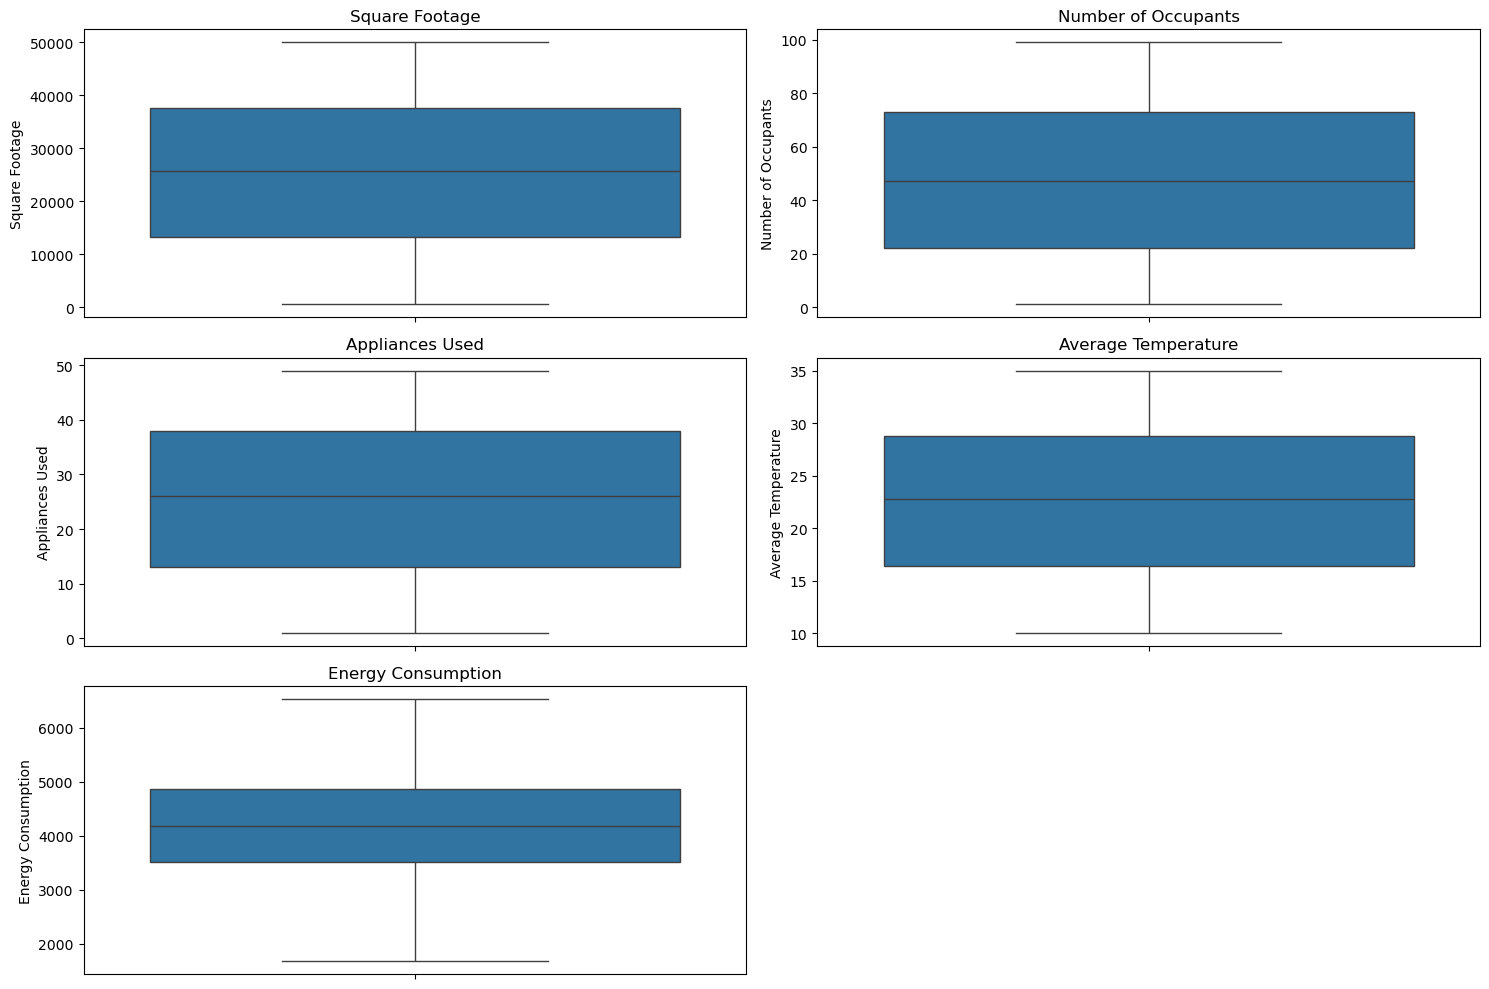

In [10]:
# Visualize the box plot for outliers
num_cols = df.select_dtypes('number').columns

plt.figure(figsize=(15, 10))

for index, col in enumerate(num_cols, 1):
    plt.subplot(3,2, index)
    sns.boxplot(data=df, y=col)
    plt.title(col)

plt.tight_layout()
plt.show()

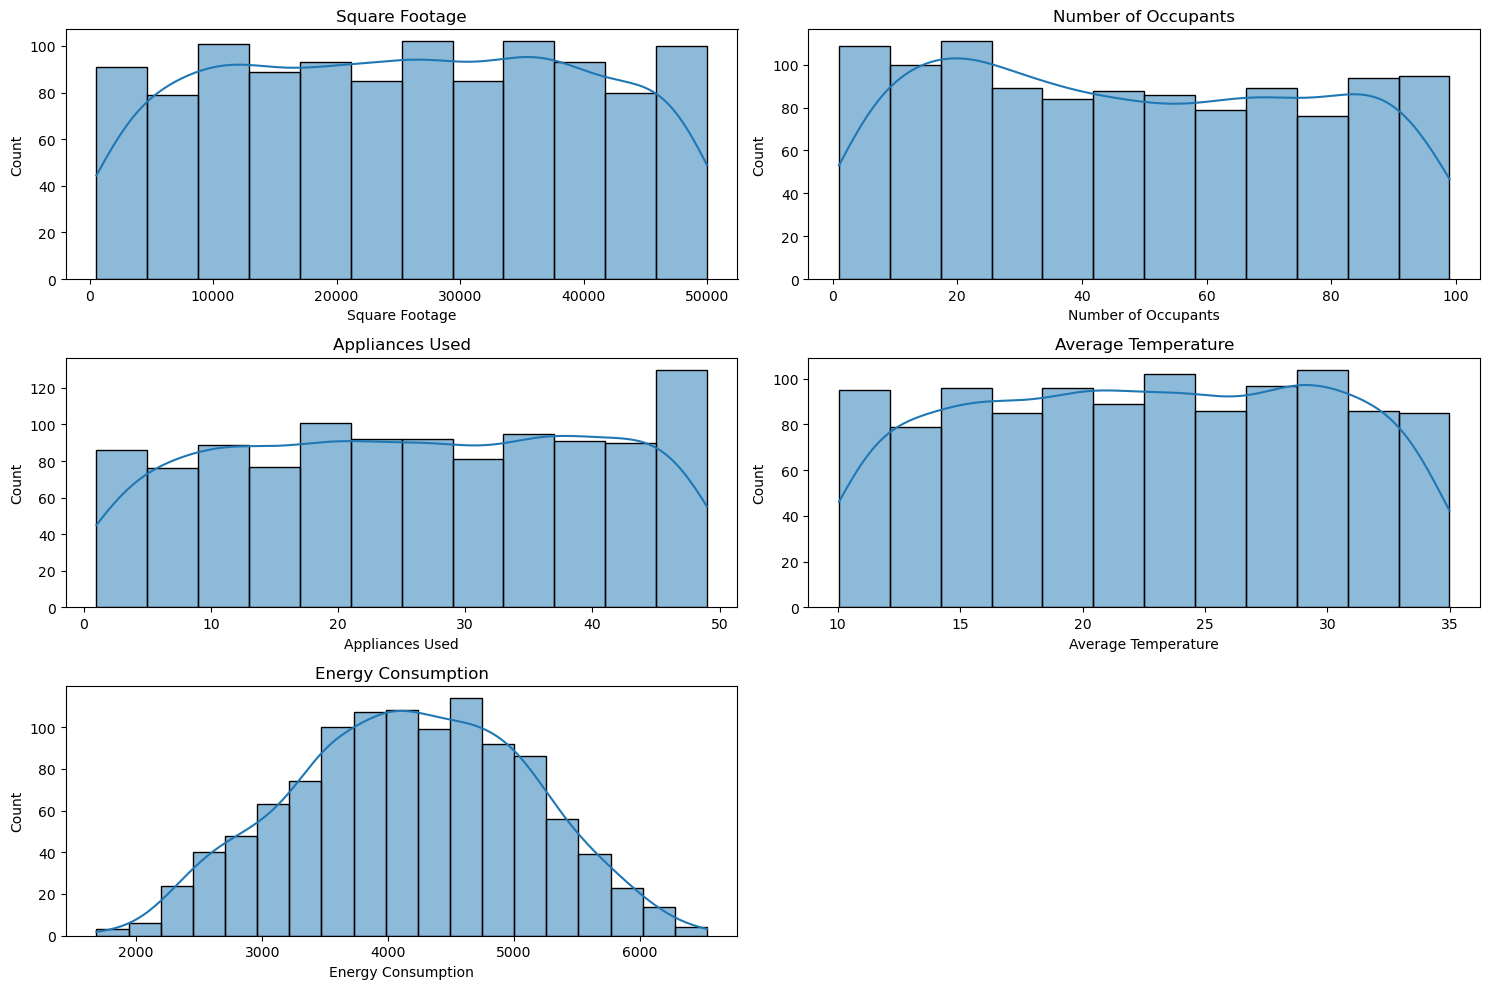

In [11]:
# Visualize the distribution of the data
num_cols = df.select_dtypes('number').columns

plt.figure(figsize=(15, 10))

for index, col in enumerate(num_cols, 1):
    plt.subplot(3,2, index)
    sns.histplot(data=df, x=col, kde=True)
    plt.title(col)

plt.tight_layout()
plt.show()

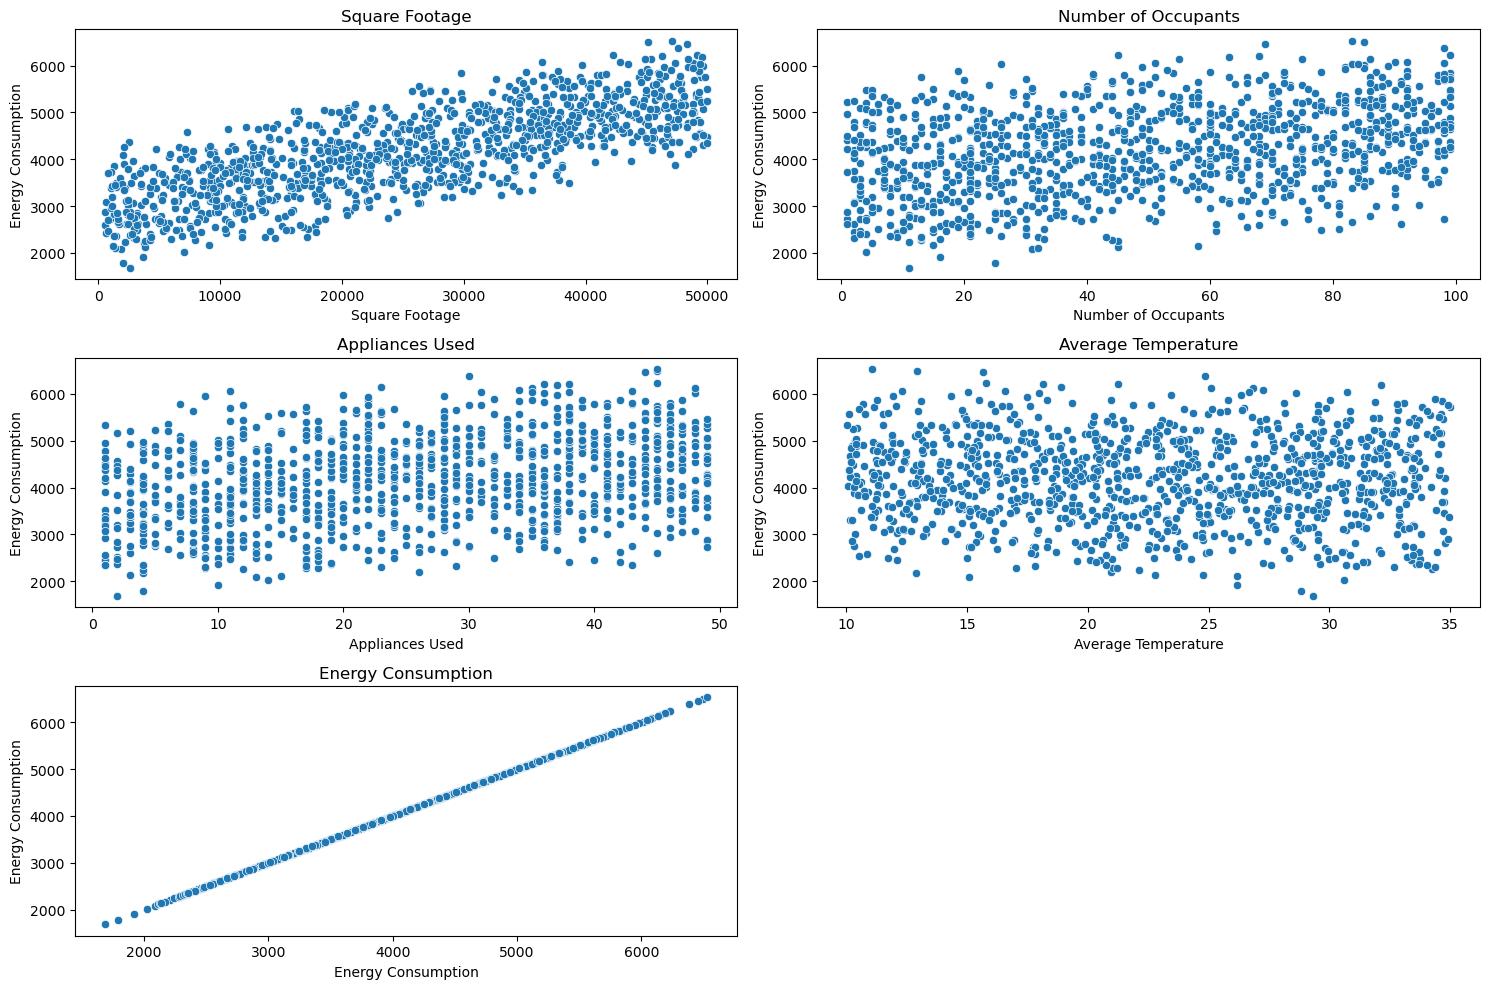

In [12]:
# Visualize The data points
num_cols = df.select_dtypes('number').columns

plt.figure(figsize=(15, 10))

for index, col in enumerate(num_cols, 1):
    plt.subplot(3,2, index)
    sns.scatterplot(data=df, x=df[col], y=df['Energy Consumption'])
    plt.title(col)

plt.tight_layout()
plt.show()

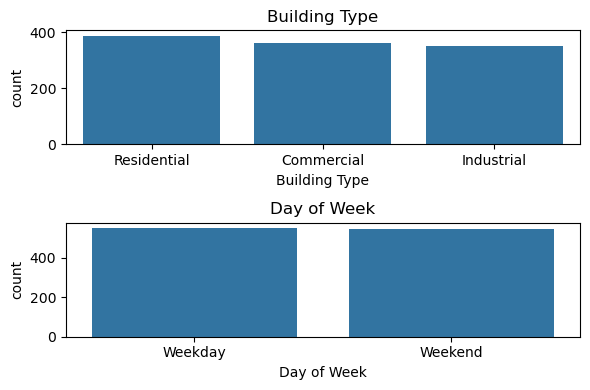

In [13]:
num_cols = df.select_dtypes('str').columns

plt.figure(figsize=(6, 4))

for index, col in enumerate(num_cols, 1):
    plt.subplot(2,1, index)
    sns.countplot(data=df, x=col)
    plt.title(col)

plt.tight_layout()
plt.show()

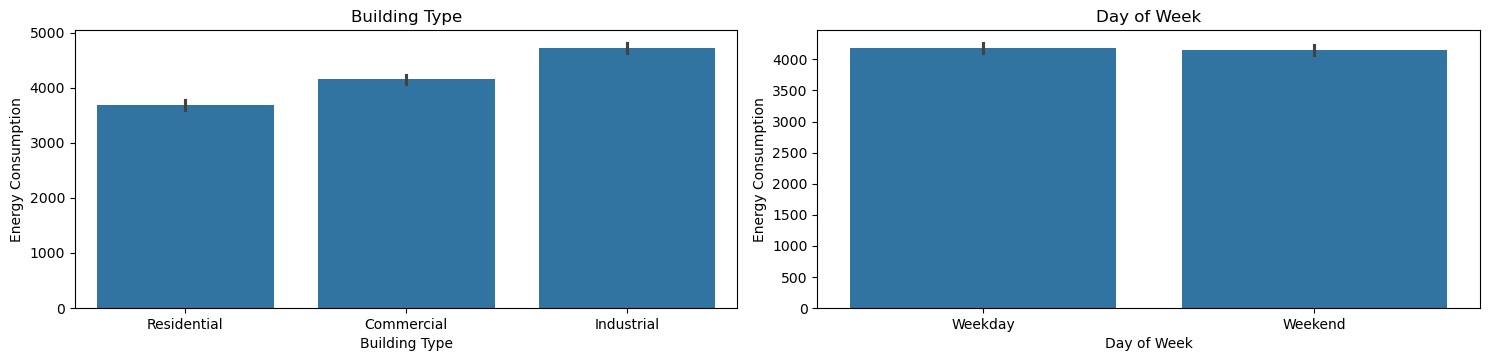

In [14]:

num_cols = df.select_dtypes('str').columns

plt.figure(figsize=(15, 10))

for index, col in enumerate(num_cols, 1):
    plt.subplot(3,2, index)
    sns.barplot(data=df, x=col, y='Energy Consumption')
    plt.title(col)

plt.tight_layout()
plt.show()

<Axes: >

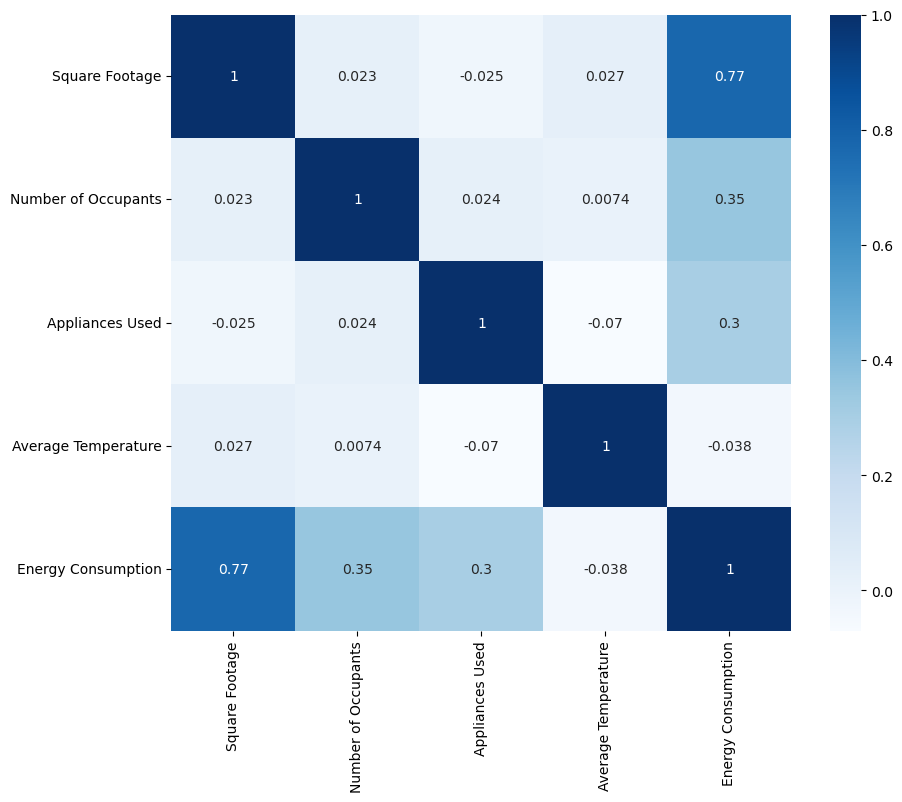

In [15]:
corr = df.select_dtypes('number').corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap='Blues')

# 3. Preprocessing

In [16]:
# Split The data
X, y = df.drop(columns= ['Energy Consumption']), df['Energy Consumption']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [17]:
display(X_train)
display(y_train)

,Building Type,Square Footage,Number of Occupants,Appliances Used,Average Temperature,Day of Week
507,Residential,23650,82,29,20.36,Weekday
551,Commercial,27205,44,14,11.38,Weekend
290,Commercial,7424,25,47,14.83,Weekday
2,Industrial,19255,37,17,14.30,Weekend
6,Industrial,38638,92,14,21.01,Weekend
...,...,...,...,...,...,...
466,Residential,14788,38,9,22.75,Weekday
121,Residential,7787,73,35,19.29,Weekday
1044,Residential,36642,36,32,11.17,Weekend
1095,Commercial,1161,81,11,15.45,Weekend


507     4030.72
551     4023.35
290     3537.04
2       4101.24
6       5526.83
         ...   
466     2735.63
121     3272.91
1044    4276.25
1095    3010.81
860     4601.21
Name: Energy Consumption, Length: 880, dtype: float64

In [18]:
# Encoding and Scaling

cat_cols = df.select_dtypes('str').columns

encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

train_encoded = encoder.fit_transform(X_train[cat_cols])
test_encoded = encoder.transform(X_test[cat_cols])

cols_names = encoder.get_feature_names_out(cat_cols)

train_encoded = pd.DataFrame(train_encoded, columns=cols_names, index=X_train.index)
test_encoded = pd.DataFrame(test_encoded, columns=cols_names, index=X_test.index)

X_train = X_train.drop(columns=cat_cols)
X_test = X_test.drop(columns=cat_cols)

X_train = pd.concat([X_train, train_encoded], axis=1)
X_test = pd.concat([X_test, test_encoded], axis=1)

In [19]:
display(X_train.head(), '\n')
display(X_test.head())

,Square Footage,Number of Occupants,Appliances Used,Average Temperature,Building Type_Commercial,Building Type_Industrial,Building Type_Residential,Day of Week_Weekday,Day of Week_Weekend
507,23650,82,29,20.36,0.0,0.0,1.0,1.0,0.0
551,27205,44,14,11.38,1.0,0.0,0.0,0.0,1.0
290,7424,25,47,14.83,1.0,0.0,0.0,1.0,0.0
2,19255,37,17,14.30,0.0,1.0,0.0,0.0,1.0
6,38638,92,14,21.01,0.0,1.0,0.0,0.0,1.0


'\n'

,Square Footage,Number of Occupants,Appliances Used,Average Temperature,Building Type_Commercial,Building Type_Industrial,Building Type_Residential,Day of Week_Weekday,Day of Week_Weekend
328,7319,21,37,31.57,0.0,1.0,0.0,1.0,0.0
688,7138,60,27,34.94,1.0,0.0,0.0,1.0,0.0
413,47537,34,17,16.60,1.0,0.0,0.0,1.0,0.0
788,30720,3,15,10.22,0.0,0.0,1.0,0.0,1.0
244,22542,58,47,32.58,0.0,0.0,1.0,0.0,1.0


In [20]:
X_train.columns

Index(['Square Footage', 'Number of Occupants', 'Appliances Used',
       'Average Temperature', 'Building Type_Commercial',
       'Building Type_Industrial', 'Building Type_Residential',
       'Day of Week_Weekday', 'Day of Week_Weekend'],
      dtype='str')

In [21]:
# Scaling
scaler = MinMaxScaler()
columns = X_train.columns
cols_names = ['Square Footage', 'Number of Occupants', 'Appliances Used',
       'Average Temperature']

X_train[cols_names] = scaler.fit_transform(X_train[cols_names])
X_test[cols_names] = scaler.transform(X_test[cols_names])

In [22]:
display(pd.DataFrame(X_train, columns=columns))
display(pd.DataFrame(X_test, columns=columns))

,Square Footage,Number of Occupants,Appliances Used,Average Temperature,Building Type_Commercial,Building Type_Industrial,Building Type_Residential,Day of Week_Weekday,Day of Week_Weekend
507,0.467059,0.826531,0.583333,0.413392,0.0,0.0,1.0,1.0,0.0
551,0.538969,0.438776,0.270833,0.053328,1.0,0.0,0.0,0.0,1.0
290,0.138843,0.244898,0.958333,0.191660,1.0,0.0,0.0,1.0,0.0
2,0.378158,0.367347,0.333333,0.170409,0.0,1.0,0.0,0.0,1.0
6,0.770233,0.928571,0.270833,0.439455,0.0,1.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...
466,0.287801,0.377551,0.166667,0.509222,0.0,0.0,1.0,1.0,0.0
121,0.146186,0.734694,0.708333,0.370489,0.0,0.0,1.0,1.0,0.0
1044,0.729858,0.357143,0.645833,0.044908,0.0,0.0,1.0,0.0,1.0
1095,0.012157,0.816327,0.208333,0.216520,1.0,0.0,0.0,0.0,1.0


,Square Footage,Number of Occupants,Appliances Used,Average Temperature,Building Type_Commercial,Building Type_Industrial,Building Type_Residential,Day of Week_Weekday,Day of Week_Weekend
328,0.136719,0.204082,0.750000,0.862871,0.0,1.0,0.0,1.0,0.0
688,0.133058,0.602041,0.541667,0.997995,1.0,0.0,0.0,1.0,0.0
413,0.950240,0.336735,0.333333,0.262630,1.0,0.0,0.0,1.0,0.0
788,0.610069,0.020408,0.291667,0.006816,0.0,0.0,1.0,0.0,1.0
244,0.444647,0.581633,0.958333,0.903368,0.0,0.0,1.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...
319,0.731456,0.663265,0.937500,0.221732,1.0,0.0,0.0,0.0,1.0
979,0.169428,0.377551,0.479167,0.532478,1.0,0.0,0.0,1.0,0.0
919,0.528997,0.602041,0.854167,0.406977,0.0,0.0,1.0,1.0,0.0
989,0.975282,0.540816,0.541667,0.309944,0.0,0.0,1.0,1.0,0.0


# Modeling

In [23]:
# Linear Regression Model
lr = LinearRegression()
lr.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](9,)","[2471.85, 980. , 960. ,...,-500. , 25. , -25. ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](9,)","['Square Footage','Number of Occupants','Appliances Used',..., 'Building Type_Residential','Day of Week_Weekday','Day of Week_Weekend']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2033
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,9
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,7


In [24]:
y_train_pred = lr.predict(X_train)

print("===================Loss==========================")
print(f"MSE: {mean_squared_error(y_train_pred, y_train)}")
print(f"MAE: {mean_absolute_error(y_train_pred, y_train)}")
print(f"R2 Score: {r2_score(y_train_pred, y_train)}")

===================Loss==========================
MSE: 0.0001849868714337007
MAE: 0.011604322503589514
R2 Score: 0.9999999997834451


In [25]:
# Test
y_pred = lr.predict(X_test)

print("===================Loss==========================")
print(f"MSE: {mean_squared_error(y_pred, y_test)}")
print(f"MAE: {mean_absolute_error(y_pred, y_test)}")
print(f"R2 Score: {r2_score(y_pred, y_test)}")

===================Loss==========================
MSE: 0.00019914006263316246
MAE: 0.011975550256244622
R2 Score: 0.999999999765886


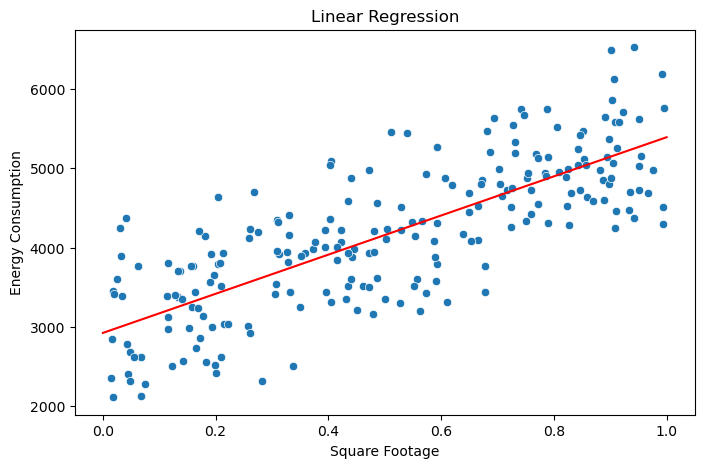

In [26]:
# Visualize Linear Regression (Square Footage vs Energy Consumption)
feature = 'Square Footage'

# Vary one feature and keep the others at their mean
grid = pd.DataFrame([X_train.mean()] * 100)
grid[feature] = np.linspace(X_train[feature].min(), X_train[feature].max(), 100)

plt.figure(figsize=(8, 5))
sns.scatterplot(x=X_test[feature], y=y_test)
plt.plot(grid[feature], lr.predict(grid), color='red')
plt.title('Linear Regression')
plt.show()

### Evaluation Metrics Summary
1. **Mean Squared Error (MSE):** Averages the squared differences between actual and predicted values (penalizes large errors heavily).
   $$MSE = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

2. **Mean Absolute Error (MAE):** Averages the absolute differences in the same unit as the target variable.
   $$MAE = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|$$

3. **R-Squared ($R^2$ Score):** Measures the proportion of variance in the target explained by the features compared to simply guessing the mean $\bar{y}$ (closer to $1$ is better).
   $$R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$

In [27]:
# Train SGDRegressor

sgd_model = SGDRegressor(
        loss="squared_error",
        max_iter=10000,
        learning_rate="constant",
        eta0=0.01,                  # Learning Rate
        random_state=42,
    )

sgd_model.fit(X_train, y_train)

,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method.Values must be in the range `[1, inf)`... versionadded:: 0.19",10000
,"random_state random_state: int, RandomState instance, default=NoneUsed for shuffling the data, when ``shuffle`` is set to ``True``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"learning_rate learning_rate: str, default='invscaling'The learning rate schedule:- 'constant': `eta = eta0`- 'optimal': `eta = 1.0 / (alpha * (t + t0))` where t0 is chosen by a heuristic proposed by Leon Bottou.- 'invscaling': `eta = eta0 / pow(t, power_t)`- 'adaptive': eta = eta0, as long as the training keeps decreasing. Each time n_iter_no_change consecutive epochs fail to decrease the training loss by tol or fail to increase validation score by tol if early_stopping is True, the current learning rate is divided by 5.- 'pa1': passive-aggressive algorithm 1, see [1]_. Only with `loss='epsilon_insensitive'`. Update is `w += eta y x` with `eta = min(eta0, loss/||x||**2)`.- 'pa2': passive-aggressive algorithm 2, see [1]_. Only with `loss='epsilon_insensitive'`. Update is `w += eta y x` with `eta = hinge_loss / (||x||**2 + 1/(2 eta0))`... versionadded:: 0.20 Added 'adaptive' option... versionadded:: 1.8 Added options 'pa1' and 'pa2'",'constant'
,"loss loss: str, default='squared_error'The loss function to be used. The possible values are 'squared_error','huber', 'epsilon_insensitive', or 'squared_epsilon_insensitive'The 'squared_error' refers to the ordinary least squares fit.'huber' modifies 'squared_error' to focus less on getting outlierscorrect by switching from squared to linear loss past a distance ofepsilon. 'epsilon_insensitive' ignores errors less than epsilon and islinear past that; this is the loss function used in SVR.'squared_epsilon_insensitive' is the same but becomes squared loss pasta tolerance of epsilon.More details about the losses formulas can be found in the:ref:`User Guide <sgd_mathematical_formulation>`.",'squared_error'
,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",'l2'
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term. The higher thevalue, the stronger the regularization. Also used to compute thelearning rate when `learning_rate` is set to 'optimal'.Values must be in the range `[0.0, inf)`.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with 0 <= l1_ratio <= 1.l1_ratio=0 corresponds to L2 penalty, l1_ratio=1 to L1.Only used if `penalty` is 'elasticnet'.Values must be in the range `[0.0, 1.0]` or can be `None` if`penalty` is not `elasticnet`... versionchanged:: 1.7 `l1_ratio` can be `None` when `penalty` is not ""elasticnet"".",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, training will stopwhen (loss > best_loss - tol) for ``n_iter_no_change`` consecutiveepochs.Convergence is checked against the training loss or thevalidation loss depending on the `early_stopping` parameter.Values must be in the range `[0.0, inf)`... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.Values must be in the range `[0, inf)`.",0


In [28]:
y_train_pred = sgd_model.predict(X_train)

print("===================Loss==========================")
print(f"MSE: {mean_squared_error(y_train_pred, y_train)}")
print(f"MAE: {mean_absolute_error(y_train_pred, y_train)}")
print(f"R2 Score: {r2_score(y_train_pred, y_train)}")

===================Loss==========================
MSE: 0.9104857207636157
MAE: 0.8037134266913321
R2 Score: 0.9999989320768038


In [29]:
y_pred = sgd_model.predict(X_test)

print("===================Loss==========================")
print(f"MSE: {mean_squared_error(y_pred, y_test)}")
print(f"MAE: {mean_absolute_error(y_pred, y_test)}")
print(f"R2 Score: {r2_score(y_pred, y_test)}")

===================Loss==========================
MSE: 0.9352431920103896
MAE: 0.8162359547467676
R2 Score: 0.9999988983407495


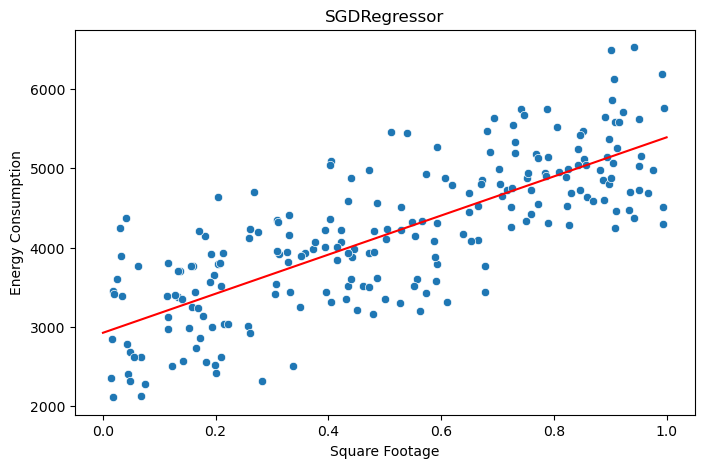

In [30]:
# Visualize SGDRegressor (Square Footage vs Energy Consumption)
plt.figure(figsize=(8, 5))
sns.scatterplot(x=X_test[feature], y=y_test)
plt.plot(grid[feature], sgd_model.predict(grid), color='red')
plt.title('SGDRegressor')
plt.show()

### Regularization Summary (L1 vs. L2)
1. **Ridge (L2):** Shrinks the weights towards zero, but they never reach exactly zero, so every feature stays in the model.
   $$Loss_{L2} = MSE + \alpha \sum_{j=1}^{n} w_j^2$$

2. **Lasso (L1):** Pushes some weights to exactly zero, which eliminates those features from the model's decision.
   $$Loss_{L1} = MSE + \alpha \sum_{j=1}^{n} |w_j|$$